In [1]:
import numpy as np
import pandas as pd
import scipy.sparse as sparse
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, describe, mode, fisher_exact
import scipy as sp
import scipy.stats as stats
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import pairwise_distances
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud
from sklearn.decomposition import NMF, non_negative_factorization
from collections import Counter
from scipy.stats import hypergeom
from scipy.stats.mstats import gmean
from scipy.cluster import hierarchy

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    print(mode(data))
    return fig

**Functions**

In [22]:
def sigmoid_func(val_arr, scaling_factor=5, method='array'):
    # max rank
    if method == 'array':
        max_val = np.max(val_arr, axis=0)
    elif method == 'full':
        max_val = np.max(val_arr)

    # scaling between [-scaling_factor, scaling_factor]
    x = (val_arr / (max_val / (scaling_factor * 2))) - scaling_factor
    sig_arr = 1 / (1 + np.exp(-x))
    return sig_arr

**Data Load**

DHS and TF

In [25]:
DHS_base_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221206.DHSsignalzscores.hdf5'
TF_base_path='/home/ctrader/region_similarity/data/rank_based/regions_25kb_CT20221214.TFsignalzscores.hdf5'

#load the data
DHS_z_hdf5 = h5py.File(DHS_base_path, 'r')
DHS_z_arr = DHS_z_hdf5['base_arr'][:]
DHS_z_hdf5.close()

TF_z_hdf5 = h5py.File(TF_base_path, 'r')
TF_z_arr = TF_z_hdf5['base_arr'][:]
TF_z_hdf5.close()

DHS_max_z_arr = np.max(DHS_z_arr, axis=1)
TF_max_z_arr = np.max(TF_z_arr, axis=1)

DHS_mean_z_arr = np.mean(DHS_z_arr, axis=1)
TF_mean_z_arr = np.mean(TF_z_arr, axis=1)

Epilogos

In [15]:
filename = '/home/ctrader/region_similarity/data/regions_25kb_CT20230103.epilogos.maxstateperbin.officialstateorder.allmapped.bed'
f = open(filename, 'r')
winning_state_data = []
for line in f.readlines():
    winning_state_data.append(np.float_(line.strip().split('|')[1].split(';')))
winning_state_data = np.array(winning_state_data)
f.close()

num_states = 18
counts = []
for region in range(len(winning_state_data)):
    region_states = (winning_state_data[region][~np.isnan(winning_state_data[region])]).astype(int)
    state_count = np.bincount(region_states)
    state_count = np.append(state_count, np.int_([0] * (num_states - len(state_count))))
    counts.append(state_count)
counts = np.array(counts)

observed = (counts.T / np.sum(counts, axis=1)).T

filename = '/home/ctrader/region_similarity/data/rank_based/epilogos.winningstateperbin.genomewide.counts.expectedratio.officialorder.CT20230103.tsv'
f = open(filename, 'r')
expected = np.float_(f.readlines()[2].strip().split('\t'))
f.close()

epi_ooe = observed / expected

epi_ooe_mean = np.nanmean(epi_ooe, axis=1)
epi_ooe_mean_corr = np.where(np.isnan(epi_ooe_mean), 0, epi_ooe_mean)

epi_ooe_mean_sqrt = np.sqrt(epi_ooe_mean_corr)

epi_ooe_max = np.nanmax(epi_ooe, axis=1)
epi_ooe_max_corr = np.where(np.isnan(epi_ooe_max), 0, epi_ooe_max)

/tmp/ipykernel_9586/164324104.py:18: RuntimeWarning: invalid value encountered in true_divide
  observed = (counts.T / np.sum(counts, axis=1)).T
/tmp/ipykernel_9586/164324104.py:27: RuntimeWarning: Mean of empty slice
  epi_ooe_mean = np.nanmean(epi_ooe, axis=1)
/tmp/ipykernel_9586/164324104.py:32: RuntimeWarning: All-NaN slice encountered
  epi_ooe_max = np.nanmax(epi_ooe, axis=1)


DescribeResult(nobs=98629, minmax=(0.0, 67.15539850019883), mean=1.0289675221132495, variance=3.727272856809665, skewness=8.02334850833514, kurtosis=132.10326324566577)
ModeResult(mode=array([0.1009542]), count=array([13580]))


Text(0.5, 1.0, 'Epilogos Mean')

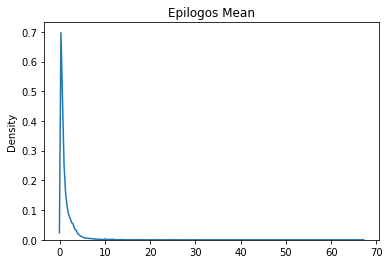

In [72]:
fig = kde_wrapper(epi_ooe_mean_corr)
plt.title('Epilogos Mean')

DescribeResult(nobs=98629, minmax=(0.0, 8.194839748292752), mean=0.7969288555265996, variance=0.39387591485248663, skewness=1.7732986486814966, kurtosis=6.568892630651554)
ModeResult(mode=array([0.3177329]), count=array([13580]))


Text(0.5, 1.0, 'Epilogos Mean -> Sqrt')

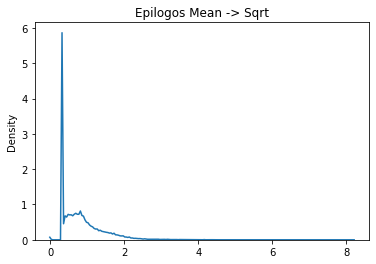

In [77]:
fig = kde_wrapper(epi_ooe_mean_sqrt)
plt.title('Epilogos Mean -> Sqrt')

DescribeResult(nobs=98629, minmax=(0.0, 1135.0933811042946), mean=9.411130633555539, variance=436.62418301270213, skewness=14.978072172456574, kurtosis=445.66956590451645)
ModeResult(mode=array([1.81717557]), count=array([13580]))


Text(0.5, 1.0, 'Epilogos Max')

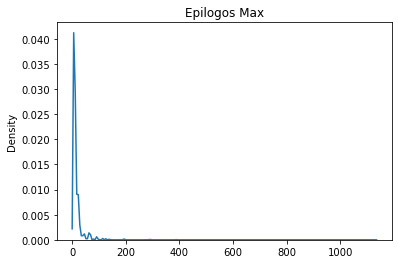

In [19]:
fig = kde_wrapper(epi_ooe_max_corr)
plt.title('Epilogos Max')

**Priors**

DHS and TF

In [37]:
DHS_min_p_arr = stats.norm.sf(DHS_max_z_arr)
TF_min_p_arr = stats.norm.sf(TF_max_z_arr)

#bonferroni correction
DHS_min_bon_p_arr = DHS_min_p_arr * len(DHS_z_arr[0])
DHS_min_bon_p_arr = np.where(DHS_min_bon_p_arr > 0.5, 0.5, DHS_min_bon_p_arr)
TF_min_bon_p_arr = TF_min_p_arr * len(TF_z_arr[0])
TF_min_bon_p_arr = np.where(TF_min_bon_p_arr > 0.5, 0.5, TF_min_bon_p_arr)

#priors
DHS_p_priors = 1 - DHS_min_p_arr
TF_p_priors = 1 - TF_min_p_arr

DHS_bon_p_priors = 1 - DHS_min_bon_p_arr
TF_bon_p_priors = 1 - TF_min_bon_p_arr

DHS_p_per_prior = []
for i in range(len(DHS_p_priors)):
    DHS_p_per_prior.append(stats.percentileofscore(DHS_p_priors, DHS_p_priors[i]))
DHS_p_per_prior = np.array(DHS_p_per_prior) / 100
DHS_p_per_sig_prior = sigmoid_func(DHS_p_per_prior)

TF_p_per_prior = []
for i in range(len(TF_p_priors)):
    TF_p_per_prior.append(stats.percentileofscore(TF_p_priors, TF_p_priors[i]))
TF_p_per_prior = np.array(TF_p_per_prior) / 100
TF_p_per_sig_prior = sigmoid_func(TF_p_per_prior)


DHS_max_per_prior = []
for i in range(len(DHS_max_z_arr)):
    DHS_max_per_prior.append(stats.percentileofscore(DHS_max_z_arr, DHS_max_z_arr[i]))
DHS_max_per_prior = np.array(DHS_max_per_prior) / 100
DHS_max_per_sig_prior = sigmoid_func(DHS_max_per_prior)

TF_max_per_prior = []
for i in range(len(TF_max_z_arr)):
    TF_max_per_prior.append(stats.percentileofscore(TF_max_z_arr, TF_max_z_arr[i]))
TF_max_per_prior = np.array(TF_max_per_prior) / 100
TF_max_per_sig_prior = sigmoid_func(TF_max_per_prior)


DHS_mean_per_prior = []
for i in range(len(DHS_mean_z_arr)):
    DHS_mean_per_prior.append(stats.percentileofscore(DHS_mean_z_arr, DHS_mean_z_arr[i]))
DHS_mean_per_prior = np.array(DHS_mean_per_prior) / 100
DHS_mean_per_sig_prior = sigmoid_func(DHS_mean_per_prior)

TF_mean_per_prior = []
for i in range(len(TF_mean_z_arr)):
    TF_mean_per_prior.append(stats.percentileofscore(TF_mean_z_arr, TF_mean_z_arr[i]))
TF_mean_per_prior = np.array(TF_mean_per_prior) / 100
TF_mean_per_sig_prior = sigmoid_func(TF_mean_per_prior)

In [103]:
np.where(DHS_p_per_sig_prior > 0.9)[0].shape

(27768,)

In [38]:
np.where(DHS_max_per_sig_prior > 0.9)[0].shape

(27644,)

In [35]:
np.where(DHS_mean_per_sig_prior > 0.9)[0].shape

(27644,)

In [104]:
np.where(TF_p_per_sig_prior > 0.9)[0].shape

(32165,)

In [40]:
np.where(TF_max_per_sig_prior > 0.9)[0].shape

(27644,)

In [36]:
np.where(TF_mean_per_sig_prior > 0.9)[0].shape

(27644,)

In [106]:
np.where(epi_ooe_mean_per_sig_prior > 0.9)[0].shape

(27644,)

DescribeResult(nobs=98629, minmax=(0.5, 1.0), mean=0.7750675736719176, variance=0.03749311145409955, skewness=-0.2765826153794733, kurtosis=-1.515108933379171)
ModeResult(mode=array([0.5]), count=array([19746]))


Text(0.5, 1.0, 'DHS Priors: 1 - p-value')

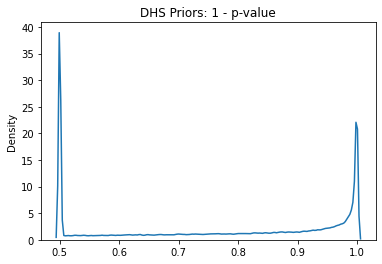

In [35]:
fig = kde_wrapper(DHS_p_priors)
plt.title('DHS Priors: 1 - p-value')

DescribeResult(nobs=98629, minmax=(0.5, 1.0), mean=0.5975869213185718, variance=0.032989679197728876, skewness=1.4693771611123703, kurtosis=0.34742986357926364)
ModeResult(mode=array([0.5]), count=array([73498]))


Text(0.5, 1.0, 'DHS Priors: 1 - bonferroni(p-value) (lower limit = 0.5)')

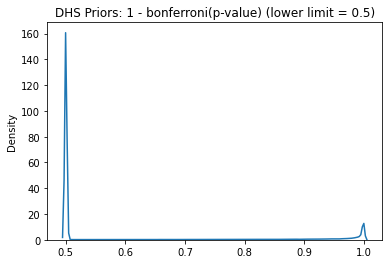

In [37]:
fig = kde_wrapper(DHS_bon_p_priors)
plt.title('DHS Priors: 1 - bonferroni(p-value) (lower limit = 0.5)')

DescribeResult(nobs=98629, minmax=(0.1001074734611524, 0.9982510215048311), mean=0.5000050695028846, variance=0.08266545102960107, skewness=0.033754365091624716, kurtosis=-1.2652459544073391)
ModeResult(mode=array([0.10010747]), count=array([19746]))


Text(0.5, 1.0, 'DHS Priors: 1 - p-value -> Percentile')

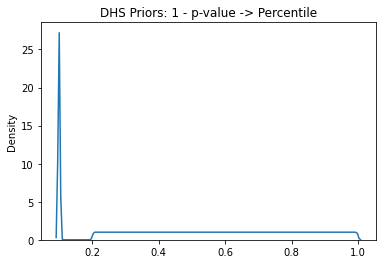

In [97]:
fig = kde_wrapper(DHS_p_per_prior)
plt.title('DHS Priors: 1 - p-value -> Percentile')

DescribeResult(nobs=98629, minmax=(0.018036239939413695, 0.9933071490757153), mean=0.5002723731964506, variance=0.152046747347608, skewness=-0.004848025106505149, kurtosis=-1.6974858297997664)
ModeResult(mode=array([0.01803624]), count=array([19746]))


Text(0.5, 1.0, 'DHS Priors: 1 - p-value -> Percentile -> Sigmoid')

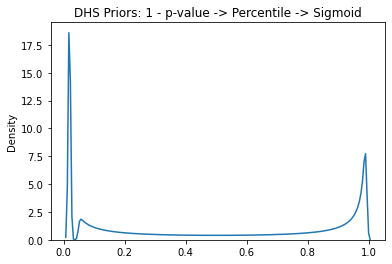

In [101]:
fig = kde_wrapper(DHS_p_per_sig_prior)
plt.title('DHS Priors: 1 - p-value -> Percentile -> Sigmoid')

DescribeResult(nobs=98629, minmax=(0.01800520252081034, 0.9933071490757153), mean=0.4994125998031977, variance=0.1518826999266001, skewness=-0.001753127574312981, kurtosis=-1.6969814225535824)
ModeResult(mode=array([0.0180052]), count=array([19746]))


Text(0.5, 1.0, 'DHS Priors: Max Z -> Percentile -> Sigmoid')

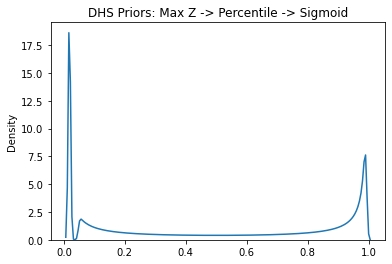

In [53]:
fig = kde_wrapper(DHS_max_per_sig_prior)
plt.title('DHS Priors: Max Z -> Percentile -> Sigmoid')

DescribeResult(nobs=98629, minmax=(0.01800520252081034, 0.9933071490757153), mean=0.4994125998035256, variance=0.15188269992673278, skewness=-0.0017531275777179873, kurtosis=-1.6969814225537025)
ModeResult(mode=array([0.0180052]), count=array([19746]))


Text(0.5, 1.0, 'DHS Priors: Mean Z -> Percentile -> Sigmoid')

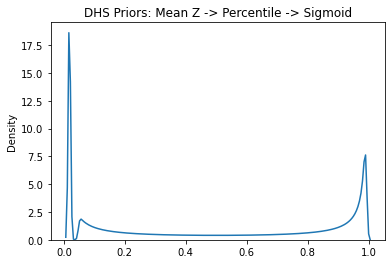

In [33]:
fig = kde_wrapper(DHS_mean_per_sig_prior)
plt.title('DHS Priors: Mean Z -> Percentile -> Sigmoid')

DescribeResult(nobs=98629, minmax=(0.5, 1.0), mean=0.9675065984061062, variance=0.014947010418593417, skewness=-3.5618209614514487, kurtosis=10.688768844346093)
ModeResult(mode=array([1.]), count=array([12564]))


Text(0.5, 1.0, 'TF Priors: 1 - p-value')

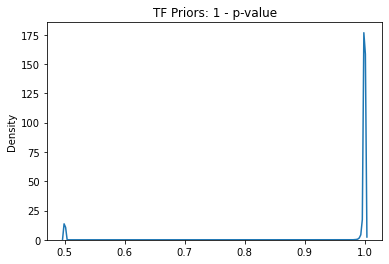

In [38]:
fig = kde_wrapper(TF_p_priors)
plt.title('TF Priors: 1 - p-value')

DescribeResult(nobs=98629, minmax=(0.5, 1.0), mean=0.8800213544721754, variance=0.03342438652922988, skewness=-1.3235045056326669, kurtosis=0.08031057959043686)
ModeResult(mode=array([0.5]), count=array([14221]))


Text(0.5, 1.0, 'TF Priors: 1 - bonferroni(p-value) (lower limit = 0.5)')

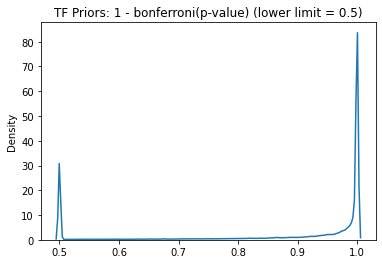

In [39]:
fig = kde_wrapper(TF_bon_p_priors)
plt.title('TF Priors: 1 - bonferroni(p-value) (lower limit = 0.5)')

DescribeResult(nobs=98629, minmax=(0.0320037717101461, 0.9363118352614344), mean=0.5000050695028846, variance=0.08314006806027018, skewness=-0.008126636057266448, kurtosis=-1.2242660215857286)
ModeResult(mode=array([0.93631184]), count=array([12564]))


Text(0.5, 1.0, 'TF Priors: 1 - p-value -> Percentile')

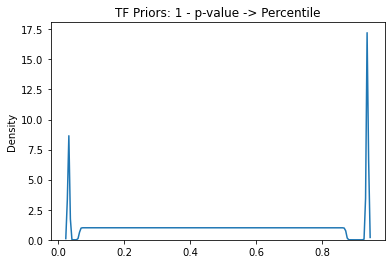

In [98]:
fig = kde_wrapper(TF_p_per_prior)
plt.title('TF Priors: 1 - p-value -> Percentile')

DescribeResult(nobs=98629, minmax=(0.009394488117593162, 0.9933071490757153), mean=0.5315937323049801, variance=0.15639230752838373, skewness=-0.11453370859051763, kurtosis=-1.7017642008586829)
ModeResult(mode=array([0.99330715]), count=array([12564]))


Text(0.5, 1.0, 'TF Priors: 1 - p-value -> Percentile -> Sigmoid')

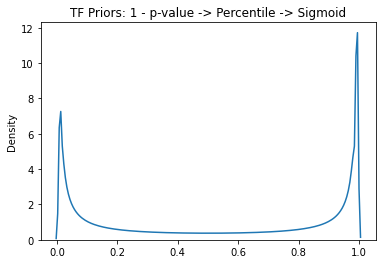

In [102]:
fig = kde_wrapper(TF_p_per_sig_prior)
plt.title('TF Priors: 1 - p-value -> Percentile -> Sigmoid')

DescribeResult(nobs=98629, minmax=(0.009194048945557922, 0.9933071490757153), mean=0.49999519110645396, variance=0.1513495472326383, skewness=-5.796921775234163e-05, kurtosis=-1.697477809705443)
ModeResult(mode=array([0.00919405]), count=array([6312]))


Text(0.5, 1.0, 'TF Priors: Max Z -> Percentile -> Sigmoid')

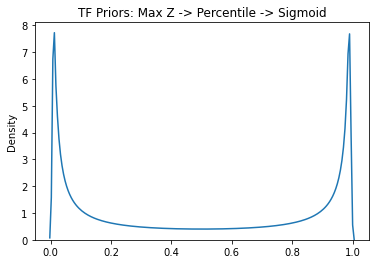

In [54]:
fig = kde_wrapper(TF_max_per_sig_prior)
plt.title('TF Priors: Max Z -> Percentile -> Sigmoid')

DescribeResult(nobs=98629, minmax=(0.009194048945557922, 0.9933071490757153), mean=0.4999951911807038, variance=0.15134954725554783, skewness=-5.796961242699933e-05, kurtosis=-1.6974778090038094)
ModeResult(mode=array([0.00919405]), count=array([6312]))


Text(0.5, 1.0, 'TF Priors: Mean Z -> Percentile -> Sigmoid')

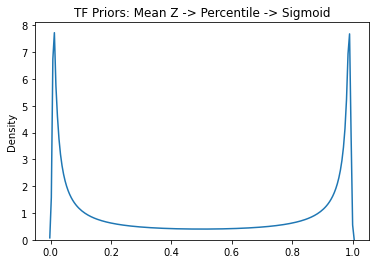

In [34]:
fig = kde_wrapper(TF_mean_per_sig_prior)
plt.title('TF Priors: Mean Z -> Percentile -> Sigmoid')

Epilogos

In [23]:
epi_sig_priors = sigmoid_func(epi_ooe_mean_corr)

epi_sqrt_sig_priors = sigmoid_func(epi_ooe_mean_sqrt)

epi_ooe_mean_per_prior = []
for i in range(len(epi_ooe_mean_corr)):
    epi_ooe_mean_per_prior.append(stats.percentileofscore(epi_ooe_mean_corr, epi_ooe_mean_corr[i]))
epi_ooe_mean_per_prior = np.array(epi_ooe_mean_per_prior) / 100

epi_ooe_mean_per_sig_prior = sigmoid_func(epi_ooe_mean_per_prior)


epi_ooe_max_per_prior = []
for i in range(len(epi_ooe_max_corr)):
    epi_ooe_max_per_prior.append(stats.percentileofscore(epi_ooe_max_corr, epi_ooe_max_corr[i]))
epi_ooe_max_per_prior = np.array(epi_ooe_max_per_prior) / 100

epi_ooe_max_per_sig_prior = sigmoid_func(epi_ooe_max_per_prior)

DescribeResult(nobs=98629, minmax=(0.0066928509242848554, 0.9933071490757153), mean=0.008499922144801643, variance=0.00021674764340510176, skewness=41.4918625377722, kurtosis=2173.0352842679977)
ModeResult(mode=array([0.00679354]), count=array([13580]))


Text(0.5, 1.0, 'Epilogos Priors: Mean -> Sigmoid')

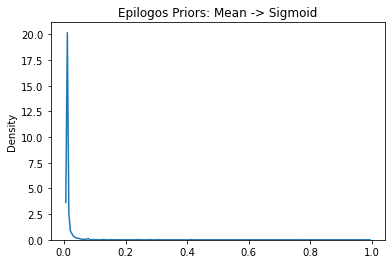

In [74]:
fig = kde_wrapper(epi_sig_priors)
plt.title('Epilogos Priors: Mean -> Sigmoid')

DescribeResult(nobs=98629, minmax=(0.0066928509242848554, 0.9933071490757153), mean=0.025382442973537568, variance=0.002051177391339153, skewness=9.993597761476062, kurtosis=138.96497510181158)
ModeResult(mode=array([0.00983157]), count=array([13580]))


Text(0.5, 1.0, 'Epilogos Priors: Mean -> sqrt -> Sigmoid')

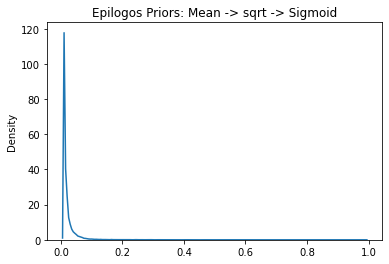

In [75]:
fig = kde_wrapper(epi_sqrt_sig_priors)
plt.title('Epilogos Priors: Mean -> sqrt -> Sigmoid')

DescribeResult(nobs=98629, minmax=(0.051688651410842654, 1.0), mean=0.5000050695028846, variance=0.08302452607115822, skewness=0.014118240520502439, kurtosis=-1.223109152001324)
ModeResult(mode=array([0.17221608]), count=array([13580]))


Text(0.5, 1.0, 'Epilogos Priors: Mean -> Percentile')

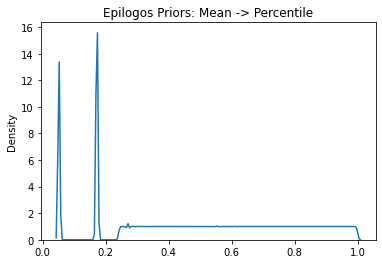

In [86]:
fig = kde_wrapper(epi_ooe_mean_per_prior)
plt.title('Epilogos Priors: Mean -> Percentile')

DescribeResult(nobs=98629, minmax=(0.011171958788326422, 0.9933071490757153), mean=0.4995965036647505, variance=0.15168955508500404, skewness=-0.0006515174480701052, kurtosis=-1.6980324699673062)
ModeResult(mode=array([0.03633931]), count=array([13580]))


Text(0.5, 1.0, 'Epilogos Priors: Mean -> Percentile -> Sigmoid')

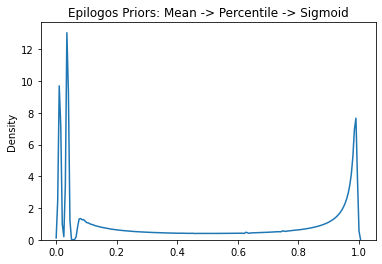

In [93]:
fig = kde_wrapper(epi_ooe_mean_per_sig_prior)
plt.title('Epilogos Priors: Mean -> Percentile -> Sigmoid')

DescribeResult(nobs=98629, minmax=(0.011171958788326422, 0.9933071490757153), mean=0.49917218821194803, variance=0.15182086434047412, skewness=0.0032718632792708272, kurtosis=-1.703739493026874)
ModeResult(mode=array([0.10014615]), count=array([13580]))


Text(0.5, 1.0, 'Epilogos Priors: Max -> Percentile -> Sigmoid')

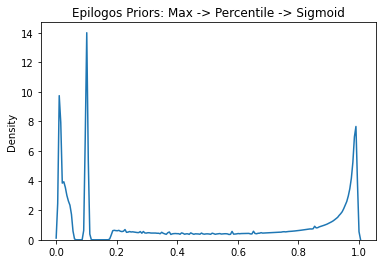

In [24]:
fig = kde_wrapper(epi_ooe_max_per_sig_prior)
plt.title('Epilogos Priors: Max -> Percentile -> Sigmoid')

What seems to work best is when we feed everyrthing into percentile and sigmoid functions. Let's look at some regions.

In [96]:
def roi_url(tier, datatype, top_regions):
    today = date.today()
    roi_url_name = 'priors_' + tier + '_regions_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    if datatype == 'epilogos':
        link_path = 'https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
    elif datatype == 'DHS':
        link_path = 'https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
    return link_path

Regions

In [10]:
# filename = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220815.sorted.c1t3.bed'
# f = open(filename, 'r')
# regions = []
# for line in f.readlines():
#     r = line.strip().split('\t')
#     regions.append(r[0] + ':' + r[1] + '-' + r[2])
# f.close()

In [74]:
filename = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220815.sorted.c1t3.bed'
f = open(filename, 'r')
regions = []
for line in f.readlines():
    r = line.strip().split('\t')
    regions.append(r)
f.close()
regions = np.array(regions)

DHS

In [115]:
#Top
print('DHS Max Top:')
top_p = -np.sort(-DHS_max_per_sig_prior)[:100]
top_r = np.argsort(-DHS_max_per_sig_prior)[:100]
top_roi = np.hstack((regions[top_r], np.round(top_p, 5).reshape(-1, 1)))
print(roi_url('top_max', 'DHS', top_roi))
    
#mid
print('DHS Max Mid:')
mid_p = -np.sort(-DHS_max_per_sig_prior)[50000:50100]
mid_r = np.argsort(-DHS_max_per_sig_prior)[50000:50100]
mid_roi = np.hstack((regions[mid_r], np.round(mid_p, 5).reshape(-1, 1)))
print(roi_url('mid_max', 'DHS', mid_roi))
    
#Low
print('DHS Max Low:')
low_p = -np.sort(-DHS_max_per_sig_prior)[70000:70100]
low_r = np.argsort(-DHS_max_per_sig_prior)[70000:70100]
low_roi = np.hstack((regions[low_r], np.round(low_p, 5).reshape(-1, 1)))
print(roi_url('low_max', 'DHS', low_roi))

DHS Max Top:
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_top_max_regions_25kb_CT20230105.bed
DHS Max Mid:
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_mid_max_regions_25kb_CT20230105.bed
DHS Max Low:
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_low_max_regions_25kb_CT20230105.bed


In [116]:
#Top
print('DHS Mean Top:')
top_p = -np.sort(-DHS_mean_per_sig_prior)[:100]
top_r = np.argsort(-DHS_mean_per_sig_prior)[:100]
top_roi = np.hstack((regions[top_r], np.round(top_p, 5).reshape(-1, 1)))
print(roi_url('top_mean', 'DHS', top_roi))
    
#mid
print('DHS Mean Mid:')
mid_p = -np.sort(-DHS_mean_per_sig_prior)[50000:50100]
mid_r = np.argsort(-DHS_mean_per_sig_prior)[50000:50100]
mid_roi = np.hstack((regions[mid_r], np.round(mid_p, 5).reshape(-1, 1)))
print(roi_url('mid_mean', 'DHS', mid_roi))
    
#Low
print('DHS Mean Low:')
low_p = -np.sort(-DHS_mean_per_sig_prior)[70000:70100]
low_r = np.argsort(-DHS_mean_per_sig_prior)[70000:70100]
low_roi = np.hstack((regions[low_r], np.round(low_p, 5).reshape(-1, 1)))
print(roi_url('low_mean', 'DHS', low_roi))

DHS Mean Top:
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_top_mean_regions_25kb_CT20230105.bed
DHS Mean Mid:
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_mid_mean_regions_25kb_CT20230105.bed
DHS Mean Low:
https://index.altius.org:1234/?application=viewer&mode=pd&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_low_mean_regions_25kb_CT20230105.bed


In [106]:
#Top
print('Epilogos Max Top:')
top_p = -np.sort(-epi_ooe_max_per_sig_prior)[:100]
top_r = np.argsort(-epi_ooe_max_per_sig_prior)[:100]
top_roi = np.hstack((regions[top_r], np.round(top_p, 5).reshape(-1, 1)))
print(roi_url('top_max', 'epilogos', top_roi))
    
#mid
print('Epilogos Max Mid:')
mid_p = -np.sort(-epi_ooe_max_per_sig_prior)[50000:50100]
mid_r = np.argsort(-epi_ooe_max_per_sig_prior)[50000:50100]
mid_roi = np.hstack((regions[mid_r], np.round(mid_p, 5).reshape(-1, 1)))
print(roi_url('mid_max', 'epilogos', mid_roi))
    
#Low
print('Epilogos Max Low:')
low_p = -np.sort(-epi_ooe_max_per_sig_prior)[70000:70100]
low_r = np.argsort(-epi_ooe_max_per_sig_prior)[70000:70100]
low_roi = np.hstack((regions[low_r], np.round(low_p, 5).reshape(-1, 1)))
print(roi_url('low_max', 'epilogos', low_roi))

Epilogos Max Top:
https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_top_max_regions_25kb_CT20230105.bed
Epilogos Max Mid:
https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_mid_max_regions_25kb_CT20230105.bed
Epilogos Max Low:
https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_low_max_regions_25kb_CT20230105.bed


In [107]:
#Top
print('Epilogos Mean Top:')
top_p = -np.sort(-epi_ooe_mean_per_sig_prior)[:100]
top_r = np.argsort(-epi_ooe_mean_per_sig_prior)[:100]
top_roi = np.hstack((regions[top_r], np.round(top_p, 5).reshape(-1, 1)))
print(roi_url('top_mean', 'epilogos', top_roi))
    
#mid
print('Epilogos Mean Mid:')
mid_p = -np.sort(-epi_ooe_mean_per_sig_prior)[50000:50100]
mid_r = np.argsort(-epi_ooe_mean_per_sig_prior)[50000:50100]
mid_roi = np.hstack((regions[mid_r], np.round(mid_p, 5).reshape(-1, 1)))
print(roi_url('mid_mean', 'epilogos', mid_roi))
    
#Low
print('Epilogos Mean Low:')
low_p = -np.sort(-epi_ooe_mean_per_sig_prior)[70000:70100]
low_r = np.argsort(-epi_ooe_mean_per_sig_prior)[70000:70100]
low_roi = np.hstack((regions[low_r], np.round(low_p, 5).reshape(-1, 1)))
print(roi_url('low_mean', 'epilogos', low_roi))

Epilogos Mean Top:
https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_top_mean_regions_25kb_CT20230105.bed
Epilogos Mean Mid:
https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_mid_mean_regions_25kb_CT20230105.bed
Epilogos Mean Low:
https://epilogos.altius.org:1234/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fpriors_low_mean_regions_25kb_CT20230105.bed


**Max seems to be the winner in terms of priors**